In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [5]:
DATA_DIR: Path = Path('../data/raw')

train_df: pd.DataFrame = pd.read_csv(DATA_DIR / 'train.csv')
val_df: pd.DataFrame = pd.read_csv(DATA_DIR / 'val.csv')
test_df: pd.DataFrame = pd.read_csv(DATA_DIR / 'test.csv')
classes_df: pd.DataFrame = pd.read_csv(DATA_DIR / 'classes.csv')

In [7]:
train_df.head()

,id,label
0,1.jpg,4
1,3.jpg,11
2,6.jpg,10
3,9.jpg,19
4,10.jpg,7


In [9]:
train_df['label'].value_counts().sort_index()

label
0     250
1     250
2     250
3     250
4     250
5     250
6     250
7     250
8     250
9     249
10    250
11    250
12    250
13    250
14    250
15    250
16    250
17    250
18    250
19    250
Name: count, dtype: int64

In [11]:
def show_image(path):
    image = Image.open(path)
    plt.imshow(image)
    plt.axis("off")
    plt.show()

Image ID: 1276.jpg
Label: 7
Class Name: medium_residential
Image Shape: (256, 256)


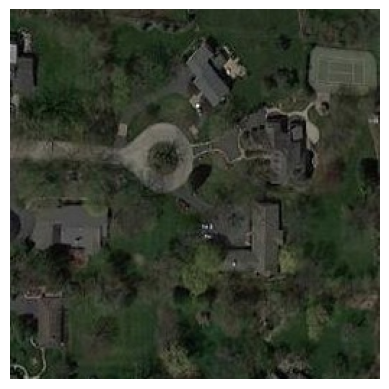

In [26]:
n = 451

print(f"Image ID: {train_df.iloc[n]['id']}")
print(f"Label: {train_df.iloc[n]['label']}")
print(f"Class Name: {classes_df[classes_df['label'] == train_df.iloc[n]['label']]['class_name'].values[0]}")
print(f"Image Shape: {Image.open(DATA_DIR / 'train' / train_df.iloc[n]['id']).size}")
show_image(DATA_DIR / "train" / train_df.iloc[n]["id"])

In [27]:
sizes = []

for filename in train_df["id"]:
    with Image.open(DATA_DIR / "train" / filename) as img:
        sizes.append(img.size)

pd.Series(sizes).value_counts().head(20)

(256, 256)    4999
Name: count, dtype: int64

In [29]:
sizes = []

for filename in test_df["id"]:
    with Image.open(DATA_DIR / "test" / filename) as img:
        sizes.append(img.size)

pd.Series(sizes).value_counts().head(20)

(256, 256)    8299
Name: count, dtype: int64

In [30]:
modes = []

for filename in train_df["id"]:
    with Image.open(DATA_DIR / "train" / filename) as img:
        modes.append(img.mode)

pd.Series(modes).value_counts()

RGB    4999
Name: count, dtype: int64

In [31]:
modes = []

for filename in test_df["id"]:
    with Image.open(DATA_DIR / "test" / filename) as img:
        modes.append(img.mode)

pd.Series(modes).value_counts()

RGB    8299
Name: count, dtype: int64